# COMP20008 (Elements of Data Processing/Machine Learning) Project

**Group Members**:
- Brian Nguyen  
- Minh Hoang Ha  
- Tony Tran
- Faiyaz Rashid

## **Research question:**  
Can grey squirrel behaviour and interaction patterns predict the time of day (AM vs PM), and what do these patterns suggest about the impact of human activity on squirrels across different times?




## Required packages:
This cell is dedicated to import all required packages for the computations


In [ ]:
# Force a specific version of Python to be ran on Google Colab
!pip install scikit-learn==1.7.2 pandas==2.3.3 numpy==2.3.5

In [ ]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    mutual_info_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    silhouette_score,
)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.patches as mpatches

from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Check current version

## Data Preprocessing
There are two data preprocessing methods being performed. The methods are:
1. Feature engineering  
2. Bag-of-words implementations for stories and specific location

#### Load the dataset
The datasets live in the `data/` folder at the repository root (paths below are relative to this `notebooks/` folder).

*On Google Colab, upload the three CSVs and change `DATA_DIR` to `'/content'`.*


In [ ]:
# File paths (relative to the notebooks/ folder)
DATA_DIR = '../data'
SQUIRREL_PATH = f'{DATA_DIR}/squirrel.csv'
HECTARE_PATH = f'{DATA_DIR}/hectare.csv'
STORIES_PATH = f'{DATA_DIR}/stories.csv'

# Load the dataset

squirrels = pd.read_csv(SQUIRREL_PATH)
hectares = pd.read_csv(HECTARE_PATH)
stories = pd.read_csv(STORIES_PATH)

#### Filter for grey squirrels

In [ ]:
squirrels = squirrels[squirrels['Primary Fur Color'] == 'Gray']

#### Calculate the individual scores
Using OrdinalEncoder, we convert binary entries of behavioural columns into numerical values. True entries are converted to the numerical 1, while False entries are converted to the numerical 0.

Then, calculate the engineered features for each of the categories above.

In [ ]:
SIGHTING_FEATURES = [
    'Running', 'Chasing', 'Climbing', 'Eating', 'Foraging', 'Kuks', 'Quaas',
    'Moans', 'Tail flags', 'Tail twitches', 'Approaches', 'Indifferent',
    'Runs from'
]
MOVEMENT_CATEGORY = ['Running_encoded', 'Chasing_encoded', 'Climbing_encoded']
FEEDING_CATEGORY = ['Eating_encoded', 'Foraging_encoded']
VOCALISATION_CATEGORY = ['Kuks_encoded', 'Quaas_encoded', 'Moans_encoded']
COMMUNICATION_CATEGORY = ['Tail flags_encoded', 'Tail twitches_encoded']
HUMAN_INTERACTION_CATEGORY = ['Approaches_encoded', 'Indifferent_encoded', 'Runs from_encoded']



encoder = OrdinalEncoder()

# Encode binary entries of the behavioural features into 0 and 1
encoded_behaviour = encoder.fit_transform(squirrels[SIGHTING_FEATURES])
encoded_col_name = [f'{col}_encoded' for col in SIGHTING_FEATURES]
squirrels[encoded_col_name] = encoded_behaviour

# Calculate the engineered features
squirrels['Movement'] = squirrels[MOVEMENT_CATEGORY].sum(axis=1)
squirrels['Feeding'] = squirrels[FEEDING_CATEGORY].sum(axis=1)
squirrels['Vocalisation'] = squirrels[VOCALISATION_CATEGORY].sum(axis=1)
squirrels['Communication'] = squirrels[COMMUNICATION_CATEGORY].sum(axis=1)
squirrels['Human interaction'] = squirrels[HUMAN_INTERACTION_CATEGORY].sum(axis=1)
squirrels['Degree of friendliness'] = squirrels['Approaches_encoded'] - squirrels['Runs from_encoded']

squirrels.head()

,X,Y,Unique Squirrel ID,Hectare,Shift,Date,Hectare Squirrel Number,Age,Primary Fur Color,Highlight Fur Color,...,Tail twitches_encoded,Approaches_encoded,Indifferent_encoded,Runs from_encoded,Movement,Feeding,Vocalisation,Communication,Human interaction,Degree of friendliness
2,-73.974281,40.775534,11B-PM-1014-08,11B,PM,10142018,8,NaN,Gray,NaN,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,-73.959641,40.790313,32E-PM-1017-14,32E,PM,10172018,14,Adult,Gray,NaN,...,0.0,0.0,0.0,1.0,0.0,2.0,0.0,0.0,1.0,-1.0
4,-73.970268,40.776213,13E-AM-1017-05,13E,AM,10172018,5,Adult,Gray,Cinnamon,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6,-73.954120,40.793181,36H-AM-1010-02,36H,AM,10102018,2,Adult,Gray,NaN,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
7,-73.958269,40.791737,33F-AM-1008-02,33F,AM,10082018,2,Adult,Gray,NaN,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


#### Normalise the columns
Finally, we normalise the new engineered categories so that they carry the same range.

In [ ]:
# NOrmalise the engineered features using MinMaxScaler
scaler = MinMaxScaler()
ENGINEERED_FEATURES_NORM = ['Movement_norm', 'Feeding_norm', 'Vocalisation_norm', 'Communication_norm', 'Human_interaction_norm', 'Degree_friendliness_norm']
ENGINEERED_FEATURES = ['Movement', 'Feeding', 'Vocalisation', 'Communication', 'Human interaction', 'Degree of friendliness']

# squirrels[ENGINEERED_FEATURES] = scaler.fit_transform(squirrels[ENGINEERED_FEATURES])
squirrels['Movement_norm'] = squirrels['Movement'] / 3
squirrels['Feeding_norm'] = squirrels['Feeding'] / 2
squirrels['Vocalisation_norm'] = squirrels['Vocalisation'] / 3
squirrels['Communication_norm'] = squirrels['Communication'] / 2
squirrels['Human_interaction_norm'] = squirrels['Human interaction'] / 3
squirrels['Degree_friendliness_norm'] = (
    squirrels['Degree of friendliness'] + 1
) / 2

squirrels[ENGINEERED_FEATURES + ENGINEERED_FEATURES_NORM].head()

,Movement,Feeding,Vocalisation,Communication,Human interaction,Degree of friendliness,Movement_norm,Feeding_norm,Vocalisation_norm,Communication_norm,Human_interaction_norm,Degree_friendliness_norm
2,1.0,0.0,0.0,0.0,0.0,0.0,0.333333,0.0,0.0,0.0,0.000000,0.5
3,0.0,2.0,0.0,0.0,1.0,-1.0,0.000000,1.0,0.0,0.0,0.333333,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.000000,0.5,0.0,0.0,0.000000,0.5
6,0.0,1.0,0.0,0.0,0.0,0.0,0.000000,0.5,0.0,0.0,0.000000,0.5
7,0.0,1.0,0.0,0.0,1.0,0.0,0.000000,0.5,0.0,0.0,0.333333,0.5


### Bag of Words
To extract keywords out of free-text data entries. The function CountVectoriser from SciKitLearn will be used to extract out common words. The function will also apply stopwords removal, lowercase conversion, as well as punctuations stripping.

In [ ]:
vectorizer = CountVectorizer(
    lowercase=True,
    stop_words = 'english'
)

# Handle empty cells
stories_note = stories['Note Squirrel & Park Stories'].fillna('')

stories_bow_matrix = vectorizer.fit_transform(stories_note)
stories_bow = pd.DataFrame(
    stories_bow_matrix.toarray(),
    columns=vectorizer.get_feature_names_out()
)
stories_bow.head()

,00,03,04,05,06,06am,07,10,100,102,...,youth,youths,yrs,yup,zero,zeroed,ziggy,zillions,zone,zoo
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## **Section 1:** Correlation Analysis  
- Pearson: Numerically encode shift column by mapping AM to 0 and PM to 1, essentually treating Shift as an ordinal variable. The resulting correlation values should indicate whether or not behaviour increases or decreases with shift, based on it being positive or negative respectively.
- MI: To properly use it with our continuous behavioural features we discretize these features into bins using qcut to create 5 equal sized bins based on the quantiles of the data. After converting them into discrete variables with values 0 through to 4, it can be properly applied to calculate dependency between Shift and the binned discrete behavioural features.

### Behaviour vs shift correlation analysis


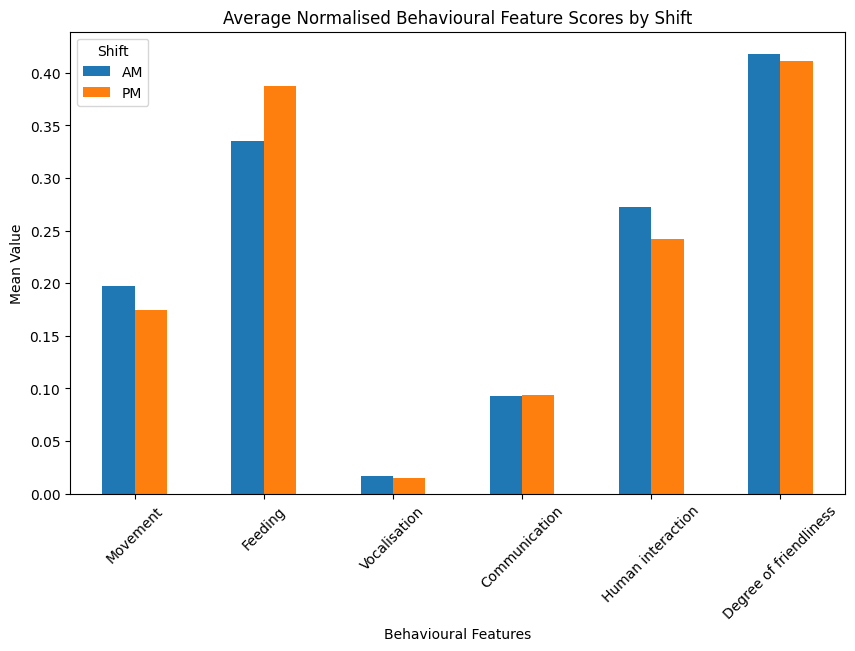

In [ ]:
# Find the mean of all features for each shift
shift_means = squirrels.groupby('Shift')[ENGINEERED_FEATURES_NORM].mean()
shift_means = shift_means.T

# Plot the graph
shift_means.plot(kind='bar', figsize=(10, 6))
plt.title('Average Normalised Behavioural Feature Scores by Shift')
plt.xlabel('Behavioural Features')
plt.ylabel('Mean Value')
plt.xticks(ticks=range(len(ENGINEERED_FEATURES)), labels=ENGINEERED_FEATURES, rotation=45)
plt.show()

### Quantitative Correlation Analysis
To quantitatively assess the relationship between engineered features and the 'Shift' (AM/PM), we can use both Pearson correlation (by encoding 'Shift' as a numerical variable) and Mutual Information. Pearson correlation measures linear relationships, while Mutual Information can capture any kind of dependency (linear or non-linear) between variables.

Human interaction        -0.096903
Movement                 -0.053976
Degree of friendliness   -0.014869
Vocalisation             -0.010682
Communication             0.002401
Feeding                   0.078873
Name: Shift_numeric, dtype: float64



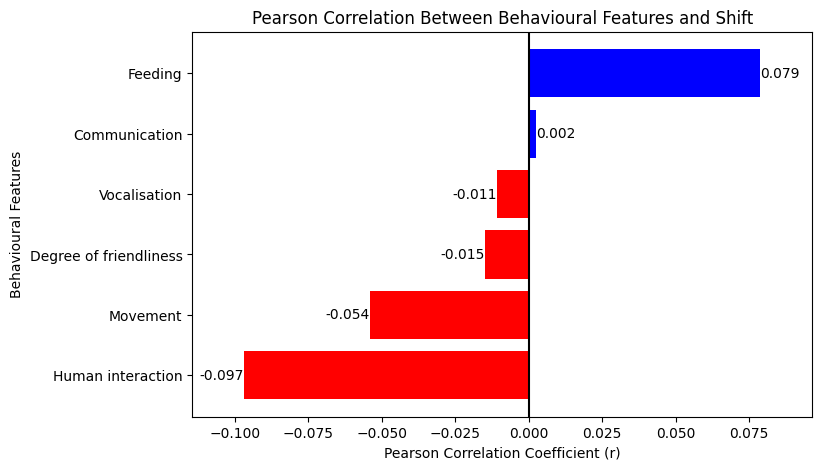

In [ ]:
# Map 'Shift' to numerical values for Pearson correlation (e.g., AM=0, PM=1)
squirrels_corr = squirrels.copy()
squirrels_corr['Shift_numeric'] = squirrels_corr['Shift'].map({'AM': 0, 'PM': 1})

# Compute Pearson correlations
pearson_correlations = squirrels_corr[
    ENGINEERED_FEATURES + ['Shift_numeric']
].corr()['Shift_numeric'][:-1]

# Sort (ascending so most negative at bottom)
pearson_correlations = pearson_correlations.sort_values()

print(pearson_correlations)
print()

# Color: blue for positive, red for negative
colors = ['blue' if val > 0 else 'red' for val in pearson_correlations]

plt.figure(figsize=(8, 5))

bars = plt.barh(pearson_correlations.index, pearson_correlations, color=colors)

# Add values to bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.3f}",
        va='center',
        ha='left' if width > 0 else 'right'
    )

plt.xlabel("Pearson Correlation Coefficient (r)")
plt.ylabel("Behavioural Features")
plt.title("Pearson Correlation Between Behavioural Features and Shift")

plt.axvline(x=0, color='black', linewidth=1.5)

# Add padding
min_val = pearson_correlations.min()
max_val = pearson_correlations.max()
padding = (max_val - min_val) * 0.1
plt.xlim(min_val - padding, max_val + padding)

plt.show()



Mutual Information with Shift (after binning continuous features):

Movement: 0.0000076402
Feeding: 0.0020845568
Vocalisation: 0.0000000000
Communication: 0.0000000000
Human interaction: 0.0003420583
Degree of friendliness: 0.0001382366



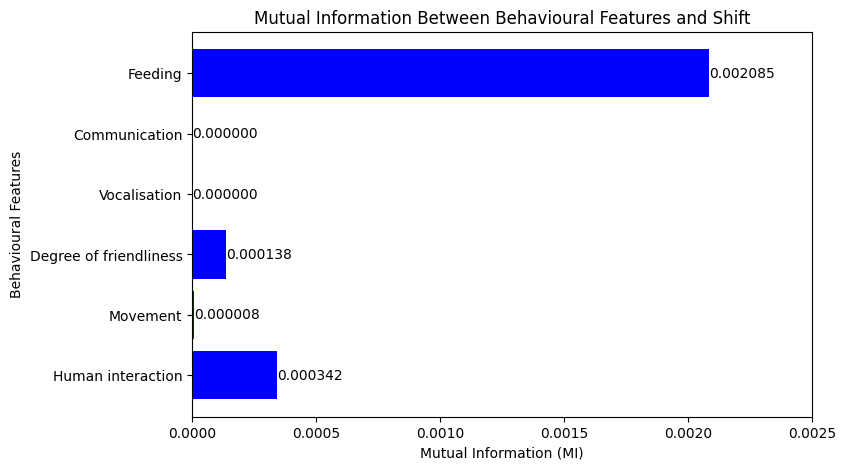

In [ ]:
# Calculate Mutual Information
mutual_info_scores_binned = {}
for feature in ENGINEERED_FEATURES:
    # Discretize the continuous feature into bins
    # Using qcut to create equal-sized bins based on quantiles
    # The number of bins (n_bins) can be adjusted
    binned_feature = pd.qcut(squirrels[feature], q=5, duplicates='drop', labels=False)

    mutual_info_scores_binned[feature] = mutual_info_score(squirrels['Shift'], binned_feature)

print("Mutual Information with Shift (after binning continuous features):\n")
for feature, score in mutual_info_scores_binned.items():
    print(f"{feature}: {score:.10f}")
print()

# Match Pearson ordering
ordered_features = pearson_correlations.index
ordered_mi = [mutual_info_scores_binned[f] for f in ordered_features]

plt.figure(figsize=(8, 5))

bars = plt.barh(ordered_features, ordered_mi, color='blue')

# Add labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"{max(width, 0):.6f}",  # prevents -0.0000
        va='center'
    )

plt.xlabel("Mutual Information (MI)")
plt.ylabel("Behavioural Features")
plt.title("Mutual Information Between Behavioural Features and Shift")

# Add padding (important for MI)
max_mi = max(ordered_mi)
plt.xlim(0, max_mi + max_mi * 0.2)

plt.show()


## **Section 2:** Supervised learning model  
Two supervised learning model will be trained to evaluate the question  
  
*Prediction of ‘Shift’ based on squirrels’ behaviour*  
  
The model will be trained using the engineered behavioural categories (Movement, Feeding, Vocalisation, Communication, Human interaction). Then, from these data, the model will classify if the "Shift" entries have the value "AM" or "PM".
  
Two models will be evaluated against each other, and their performance may be evaluated against each other. The models that will be used are:  
- K Nearest Neighbour classifier,  
- Decision Tree  

### Baseline Binary Random Model
We include a binary random model, in which the model predicts 'AM' 50% of the time, and predicts 'PM' 50% of the time. This is used as a baseline to evalute the performance of the other supervised model.

              precision    recall  f1-score   support

          AM       0.45      0.51      0.48       215
          PM       0.58      0.53      0.55       280

    accuracy                           0.52       495
   macro avg       0.52      0.52      0.52       495
weighted avg       0.53      0.52      0.52       495



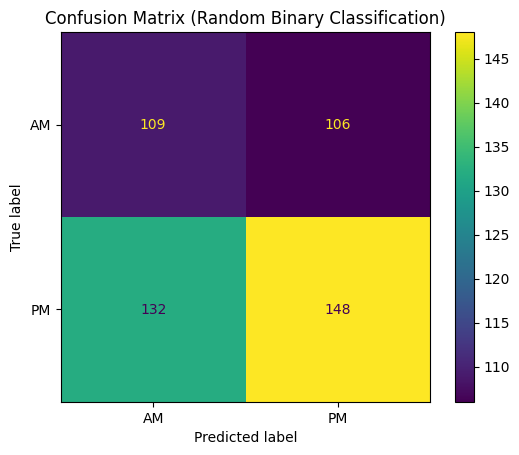

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    squirrels[ENGINEERED_FEATURES_NORM],
    squirrels['Shift'],
    test_size=0.2,
    random_state=42
)

baseline = DummyClassifier(strategy='uniform', random_state=42)

baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)

print(classification_report(y_test, y_pred_baseline))

cm = confusion_matrix(y_test,
                      y_pred_baseline,
                      labels=['AM', 'PM']
                      )

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['AM', 'PM'])

disp.plot()
plt.title("Confusion Matrix (Random Binary Classification)")
plt.show()

### K Nearest Neighbour Classifier  
The KNN algorithm works by finding the category that `k` neigbours has, and therefore classify the test data.

#### Stratified K-Fold Cross Validation
We perform Stratified K-Fold cross validation technique to determine which k value maximises the supervised model's performance. First we divide our test dataset into a training and testing portion to an $ 80:20 $ ratio. We then split the train data into 5 equal portions (folds). Then, we use 4 of the folds to train our KNN model, and use the other fold as our test data. This means that we are splitting our data into an $ 80:20 $ ratio for $ \text{Training} : \text{Testing} $. We repeat this step, until all the fold has been considered as test data once. This method allows for us to choose which is the best K value to choose when considering the number of neighbours for KNN model. It also allows us to evaluate whether if there is an issue with overfitting/underfitting with our chosen k value.

In [ ]:
ENGINEERED_FEATURES_NORM = ['Movement_norm', 'Feeding_norm', 'Vocalisation_norm', 'Communication_norm', 'Human_interaction_norm', 'Degree_friendliness_norm']
K_VALUES = range(1, 50 )

X = squirrels[ENGINEERED_FEATURES_NORM]
y = squirrels['Shift']
results = []

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)



# Split dataset into 5 folds for cross-validation (80/20) split
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for k in K_VALUES:
    knn = KNeighborsClassifier(n_neighbors=k, algorithm='brute', metric='euclidean', weights='distance')
    cv_results = cross_validate(
        knn,
        X_train,
        y_train,
        cv=cv,
        scoring=[
            'accuracy', 'recall_weighted', 'precision_weighted', 'f1_weighted'
        ],
        return_train_score=True
    )

    results.append({
        'k': k,
        'train_accuracy': cv_results['train_accuracy'].mean(),
        'test_accuracy': cv_results['test_accuracy'].mean(),
        'test_recall_weighted': cv_results['test_recall_weighted'].mean(),
        'test_precision_weighted': cv_results['test_precision_weighted'].mean(),
        'test_f1_weighted': cv_results['test_f1_weighted'].mean(),
    })

results_df = pd.DataFrame(results)




From this, we determine which k value provides the best matrics. The matrics considered are accuracy, recall, precision, and f1 scores.

In [ ]:
best_accuracy = results_df.loc[results_df['test_accuracy'].idxmax()]
best_recall = results_df.loc[results_df['test_recall_weighted'].idxmax()]
best_precision = results_df.loc[results_df['test_precision_weighted'].idxmax()]
best_f1 = results_df.loc[results_df['test_f1_weighted'].idxmax()]

print("Best k by accuracy:")
print(best_accuracy)

print("\nBest k by weighted recall:")
print(best_recall)

print("\nBest k by weighted precision:")
print(best_precision)

print("\nBest k by weighted F1:")
print(best_f1)

Best k by accuracy:
k                          41.000000
train_accuracy              0.625125
test_accuracy               0.563188
test_recall_weighted        0.563188
test_precision_weighted     0.551733
test_f1_weighted            0.540109
Name: 40, dtype: float64

Best k by weighted recall:
k                          41.000000
train_accuracy              0.625125
test_accuracy               0.563188
test_recall_weighted        0.563188
test_precision_weighted     0.551733
test_f1_weighted            0.540109
Name: 40, dtype: float64

Best k by weighted precision:
k                          44.000000
train_accuracy              0.619690
test_accuracy               0.560143
test_recall_weighted        0.560143
test_precision_weighted     0.556839
test_f1_weighted            0.545728
Name: 43, dtype: float64

Best k by weighted F1:
k                          35.000000
train_accuracy              0.610211
test_accuracy               0.553052
test_recall_weighted        0.553052
test_pre

#### Performing KNN with the optimal ` k = 35 `.
We run another instance of KNN with our determined optimal ` k = 35 `. We now train the model on the whole 80% of the train data, and evaluate on the unseen 20% test data.


In [ ]:
# Create a KNN model with k=35
optimal_knn = KNeighborsClassifier(n_neighbors=35, algorithm='brute', metric='euclidean', weights='distance')
optimal_knn.fit(X_train, y_train)

# Find the accuracy for the test set
y_pred = optimal_knn.predict(X_test)


# Output the model performance metrics
print('The KNN model with k=35 has the following performance on the test set:')
print(classification_report(y_test, y_pred))

The KNN model with k=35 has the following performance on the test set:
              precision    recall  f1-score   support

          AM       0.49      0.46      0.48       215
          PM       0.61      0.64      0.62       280

    accuracy                           0.56       495
   macro avg       0.55      0.55      0.55       495
weighted avg       0.56      0.56      0.56       495



After performing K-nn classifier, we display the result using a Confusion Matrix to show the accuracy of the model.

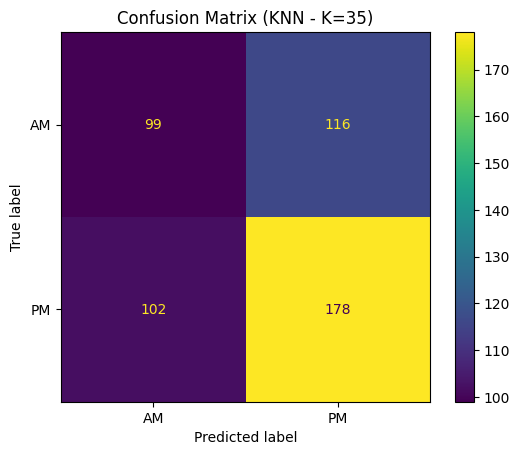

In [ ]:
cm = confusion_matrix(y_test,
                      y_pred,
                      labels=['AM', 'PM']
                      )

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['AM', 'PM'])

disp.plot()
plt.title("Confusion Matrix (KNN - K=35)")
plt.show()

We do one last test to evaluate whether if normalisation of the engineered data improved the KNN model

In [ ]:
K_VALUES = range(1, 50 )

X_train, X_test, y_train, y_test = train_test_split(
    squirrels[ENGINEERED_FEATURES],
    squirrels['Shift'],
    test_size=0.2,
    random_state=42
)

X = squirrels[ENGINEERED_FEATURES]
y = squirrels['Shift']
results = []

# Split dataset into 5 folds for cross-validation (80/20) split
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Create a KNN model with k=35
optimal_knn = KNeighborsClassifier(n_neighbors=35, algorithm='brute', metric='euclidean', weights='distance')
optimal_knn.fit(X_train, y_train)

# Find the accuracy for the test set
y_pred = optimal_knn.predict(X_test)

# Output the model performance metrics
print('The KNN model with k=35 has the following performance on the test set:')
print(classification_report(y_test, y_pred))



The KNN model with k=35 has the following performance on the test set:
              precision    recall  f1-score   support

          AM       0.49      0.46      0.47       215
          PM       0.60      0.63      0.62       280

    accuracy                           0.56       495
   macro avg       0.55      0.54      0.54       495
weighted avg       0.55      0.56      0.55       495



### Decision Tree:


#### Stratified K-Fold Cross Validation
We perform Stratified K-Fold cross validation technique to determine which tree_depth we should use

In [ ]:
DEPTH_VALUE = range(1, 16)

X = squirrels[ENGINEERED_FEATURES_NORM]
y = squirrels['Shift']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

results = []

# Split dataset into 5 folds for cross-validation (80/20) split
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for depth in DEPTH_VALUE:
    dt = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=42)
    cv_results = cross_validate(
        dt,
        X_train,
        y_train,
        cv=cv,
        scoring=[
            'accuracy', 'recall_weighted', 'precision_weighted', 'f1_weighted'
        ],
        return_train_score=True
    )

    results.append({
        'depth': depth,
        'train_accuracy': cv_results['train_accuracy'].mean(),
        'test_accuracy': cv_results['test_accuracy'].mean(),
        'test_recall_weighted': cv_results['test_recall_weighted'].mean(),
        'test_precision_weighted': cv_results['test_precision_weighted'].mean(),
        'test_f1_weighted': cv_results['test_f1_weighted'].mean(),
    })

results_df = pd.DataFrame(results)

best_accuracy = results_df.loc[results_df['test_accuracy'].idxmax()]
best_recall = results_df.loc[results_df['test_recall_weighted'].idxmax()]
best_precision = results_df.loc[results_df['test_precision_weighted'].idxmax()]
best_f1 = results_df.loc[results_df['test_f1_weighted'].idxmax()]

print("Best k by accuracy:")
print(best_accuracy)

print("\nBest k by weighted recall:")
print(best_recall)

print("\nBest k by weighted precision:")
print(best_precision)

print("\nBest k by weighted F1:")
print(best_f1)

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/dist-packag

Best k by accuracy:
depth                      8.000000
train_accuracy             0.612867
test_accuracy              0.582922
test_recall_weighted       0.582922
test_precision_weighted    0.574376
test_f1_weighted           0.552040
Name: 7, dtype: float64

Best k by weighted recall:
depth                      8.000000
train_accuracy             0.612867
test_accuracy              0.582922
test_recall_weighted       0.582922
test_precision_weighted    0.574376
test_f1_weighted           0.552040
Name: 7, dtype: float64

Best k by weighted precision:
depth                      4.000000
train_accuracy             0.592139
test_accuracy              0.582919
test_recall_weighted       0.582919
test_precision_weighted    0.577211
test_f1_weighted           0.531404
Name: 3, dtype: float64

Best k by weighted F1:
depth                      9.000000
train_accuracy             0.616406
test_accuracy              0.582418
test_recall_weighted       0.582418
test_precision_weighted    0.5736

From here, we identified that the optimal depth for decision Tree is `max_depth = 9 `

Accuracy: 0.5919
              precision    recall  f1-score   support

          AM       0.55      0.35      0.43       215
          PM       0.61      0.78      0.68       280

    accuracy                           0.59       495
   macro avg       0.58      0.56      0.55       495
weighted avg       0.58      0.59      0.57       495



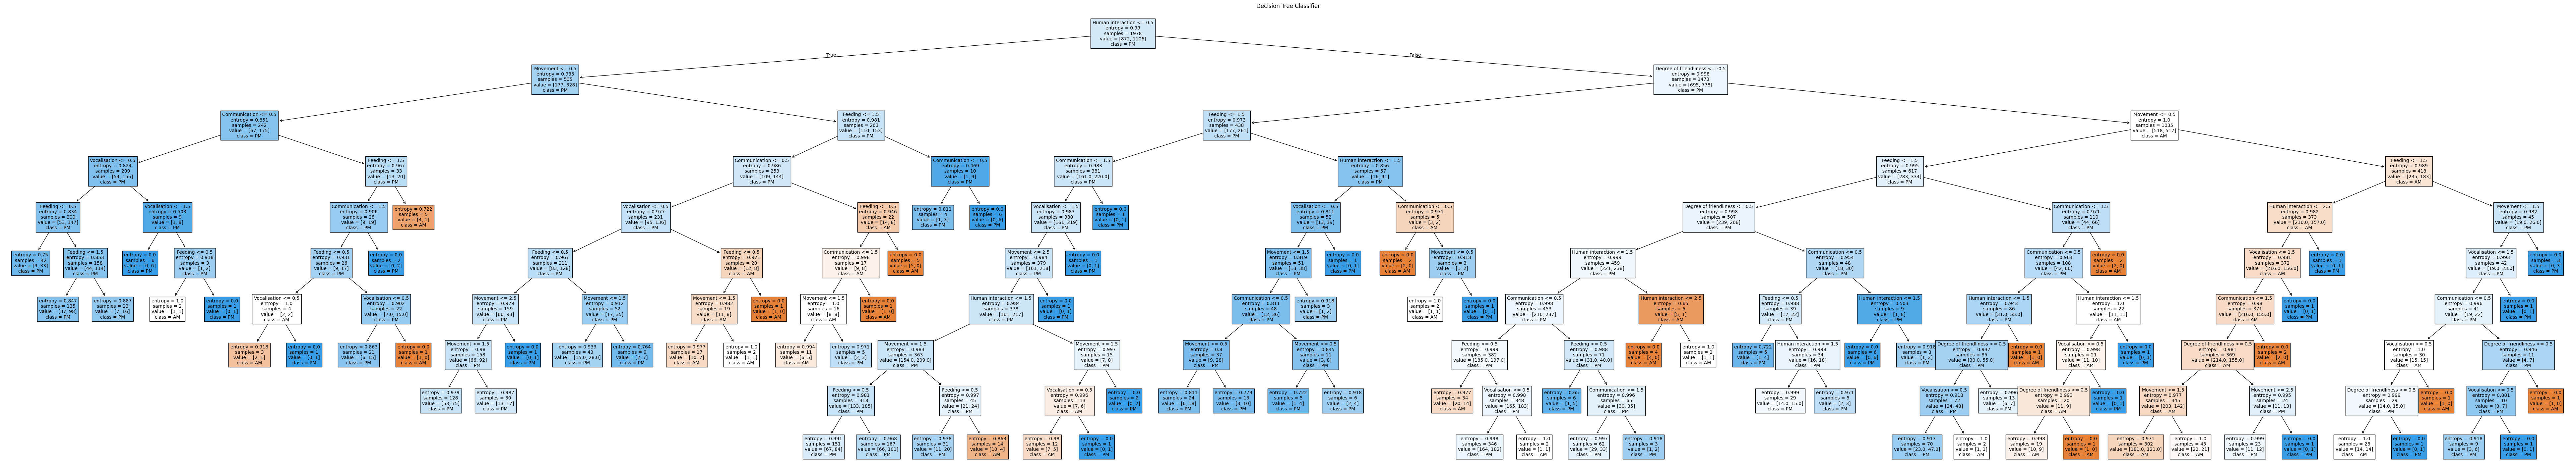

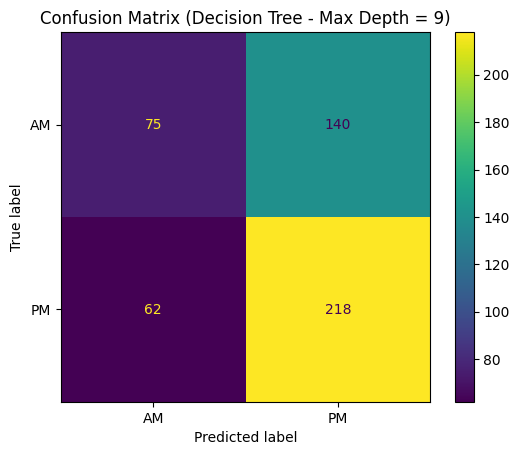

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    squirrels[ENGINEERED_FEATURES],
    squirrels['Shift'],
    test_size=0.2,
    random_state=42
)

dt = DecisionTreeClassifier(criterion='entropy', max_depth=9, random_state=42)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test, y_pred_dt):.4f}')
print(classification_report(y_test, y_pred_dt))

plt.figure(figsize=(100, 18))
plot_tree(dt,
          feature_names=ENGINEERED_FEATURES,
          class_names=['AM', 'PM'],
          filled=True,
          fontsize=10)
plt.title("Decision Tree Classifier")
plt.show()

cm = confusion_matrix(y_test,
                      y_pred_dt,
                      labels=['AM', 'PM']
                      )

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['AM', 'PM'])

disp.plot()
plt.title("Confusion Matrix (Decision Tree - Max Depth = 9)")
plt.show()

## **Section 3:** Clustering

The cluster method that will be done is K-means clustering. First, the elbow method will be run to find the optimal k value for clustering. Then, clustering will be performed based on the optimal k values.

### Functions from Assignment 1

The following are functions taken from 2026s1 COMP20008 Assignment 1, written by Tony Tran. The functions are slightly altered to match the required task.

In [ ]:
import os

BACKGROUND_PATH = '../assets/centralpark.png'
COLOUR_MAP = {0: 'red', 1: 'green', 2: 'blue', 3: 'orange', 4: 'purple'}
X_MIN = -73.992919921875
X_MAX = -73.948974609375
Y_MIN = 40.75557964275589
Y_MAX = 40.805493843894155
# X_MIN = -74
# X_MAX = -73.9
# Y_MIN = 40.75557964275589
# Y_MAX = 40.805493843894155

def plot_line_chart(
    x_values,
    y_values,
    graph_title,
    x_label,
    y_label,
    graph_width,
    graph_height
):
    """Plot a line chart based on the inputted list.

    Args:
        * x_values: a list of floating points containing the x-values of the data
        to be plotted.
        * y_values: a list of floating points containing the y-values of the data
        to be plotted.
        * graph_title: a string containing the graph's title.
        * x_label: a string containing the x-axis label for the graph.
        * y_label: a string containing the y-axis label for the graph.
        * graph_width: a floating point containing the width of the output graph.
        * graph_height: a floating point containing the height of the output graph.

    Returns:
        None
    """
    plt.figure(figsize=(graph_width, graph_height))
    plt.plot(x_values, y_values, marker='x')

    # Add graph labels:
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(graph_title)

    plt.show()

def elbow_method(sighting_date_data, k_range, shift):
    """Function to perform the elbow method, by performing a range of KMeans and
    plotting a graph between different k values and its respective Sum of Squared
    Errors (SSE)

    Args:
        * sighting_date_data: a pandas DataFrame containing the dataset of encoded
        Sighting features, as well as the Date being normalised.
        * k_range: a list of integers containing the different number of clusters
        that we should perform K-Means on.
        * shift: a string containing the shift of the squirrels data, either 'AM' or 'PM'.

    Returns:
        None
    """
    # Perform k-Means for k in specified range
    sse = []

    # Get clusters from specified values
    for k in k_range:
        clusters = KMeans(n_clusters=k, n_init=40, random_state=42)
        clusters.fit(sighting_date_data)
        sse.append(clusters.inertia_)

    # Plot the line graph between different values of k and its sse
    plot_line_chart(
        k_range,
        sse,
        (
            f'Relationship between the Sum of Squared Errors and the number of\n'
            f'clusters used for K-Means cluster method ({shift} shift)'
        ),
        'Number of Clusters',
        'Sum of Squared Errors',
        10,
        6)

def plot_scatter_chart(
    x_values,
    y_values,
    graph_title,
    x_label,
    y_label,
    colour_map,
    colour_label
):
    """Plot a scatter chart based on the inputted list.

    Args:
        * x_values: a list of floating points containing the x-values of the data
        to be plotted.
        * y_values: a list of floating points containing the y-values of the data
        to be plotted.
        * graph_title: a string containing the graph's title.
        * x_label: a string containing the x-axis label for the graph.
        * y_label: a string containing the y-axis label for the graph.
        * colour_map: a dictionary mapping which data label should have which colour.
        * colour_label: a list of integer or string containing the data label.

    Returns:
        None
    """
    plot, ax = plt.subplots(figsize=(12, 8))
    # Optional map background (not committed to the repo, see README)
    if os.path.exists(BACKGROUND_PATH):
        background_im = plt.imread(BACKGROUND_PATH)
        ax.imshow(background_im, extent=[X_MIN, X_MAX, Y_MIN, Y_MAX])
    # plt.figure(figsize=(12, 8))
    ax = plt.scatter(
        x_values,
        y_values,
        c=[colour_map.get(x) for x in colour_label],
        s=10
    )
    # ax.set_xlim(X_MIN, X_MAX)
    # ax.set_ylim(Y_MIN, Y_MAX)

    # Add legend for cluster colours
    unique_labels = sorted(set(colour_label))

    legend_handles = [
        mpatches.Patch(
            color=colour_map[label],
            label=f"Cluster {label}"
        )
        for label in unique_labels
    ]

    plt.legend(handles=legend_handles, title="Cluster")

    # Add axis label
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(graph_title)

    plt.show()

### Elbow method   
First, we perform the elbow method to see which k value is the optimal number of cluster. Then, using that value, we redo the clusters, and plot the scatter plot to identify if there are any cluster of interest for squirrel behaviours in AM

#### AM Clustering

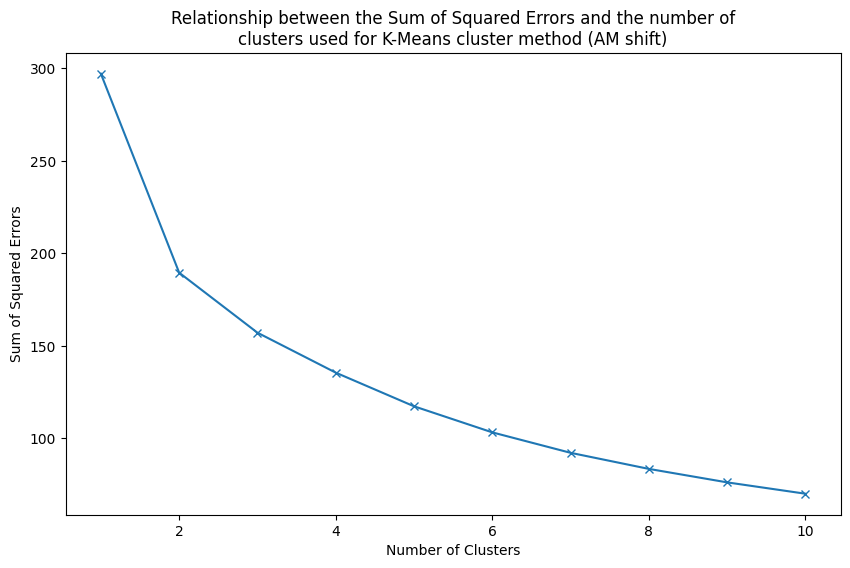

In [ ]:
am_squirrels = squirrels[squirrels['Shift'] == 'AM']

am_behaviour_data = am_squirrels[ENGINEERED_FEATURES_NORM]

elbow_method(am_behaviour_data, range(1, 11), 'AM')

#### PM Clustering

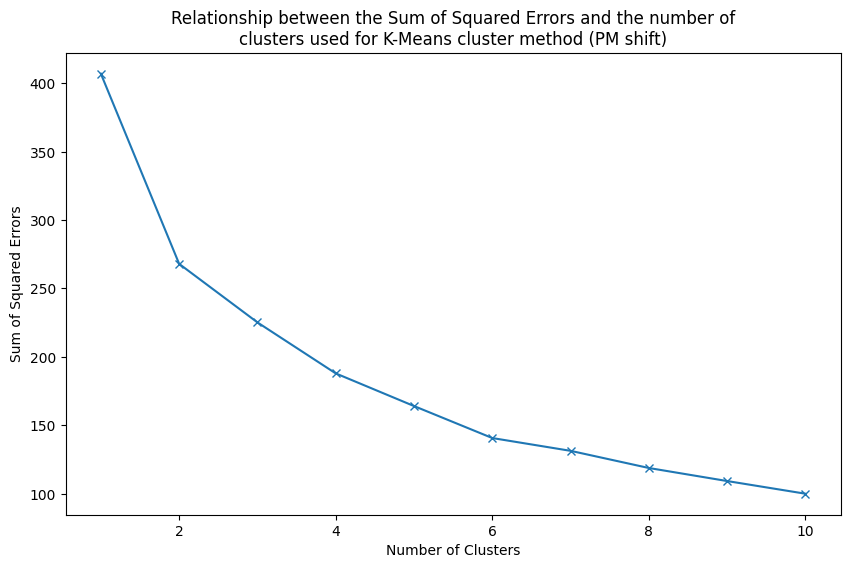

In [ ]:
pm_squirrels = squirrels[squirrels['Shift'] == 'PM']

pm_behaviour_data = pm_squirrels[ENGINEERED_FEATURES_NORM]

elbow_method(pm_behaviour_data, range(1, 11), 'PM')

### Optimal k values
From the sse graph, we find that the optimal cluster occurs at $k=3$.  
Thus, we perform K-Means cluster with $k=3$ for AM and PM data

#### Function to generate cluster  
First, we create a reusable function to perform k-means cluster for the chosen k-value

In [ ]:
def behavioural_cluster(
    squirrels,
    behaviour_data,
    optimal_k,
    shift,
    is_kmeans=True
):
    """"Perform KMeans clustering method based on the provided optimal number of
    cluster for behavioural features. Then, plot a scatter plot to illustrate the
    cluster.

    Args:
        * squirrels: a pandas DataFrame containing squirrels dataset that is read
        from 'data/squirrel.csv'.
        * behaviour_data: a pandas DataFrame containing the encoded behaviour
        features.
        * optimal_k: an integer containing the optimal number of cluster to perform
        K-Means cluster method.
        * shift: a string containing the shift of the squirrels data, either 'AM' or 'PM'.

    Returns:
        * cluster_data: a pandas DataFrame containing relevant data to categorise
        squirrels data.
    """
    # Perform K-Means with k=3
    cluster = KMeans(n_clusters=optimal_k, random_state=42)
    cluster.fit(behaviour_data)

    # Save back important data from K-Means cluster
    distance_from_centre = cluster.transform(behaviour_data)
    cluster_data = pd.DataFrame({
        'sighting_cluster': cluster.labels_,
        'sighting_cluster_distance': distance_from_centre[
            range(len(squirrels)),
            cluster.labels_
        ]
    })

    #  Display cluster centres data
    centres = pd.DataFrame(
        cluster.cluster_centers_,
        columns=behaviour_data.columns
    )

    print(centres)
    if is_kmeans:
      # Plot the scatter plot
      plot_scatter_chart(
          squirrels['X'],
          squirrels['Y'],
      (
          f"Behavioural cluster distribution across Central Park: {shift} shift\n"
          f"K-Means behavioural clustering (k={optimal_k})"
      ),
          'X',
          'Y',
          COLOUR_MAP,
          cluster_data['sighting_cluster']
      )
    else:
      # Plot the scatter plot
      plot_scatter_chart(
          squirrels['X'],
          squirrels['Y'],
      (
          f"Behavioural cluster distribution across Central Park: {shift} shift\n"
          f"Agglomerative behavioural clustering"
      ),
          'X',
          'Y',
          COLOUR_MAP,
          cluster_data['sighting_cluster']
      )

#### AM  
Perform K-Means clustering for squirrel sightings in AM shift

   Movement_norm  Feeding_norm  Vocalisation_norm  Communication_norm  \
0       0.070085      0.589744           0.007977            0.083761   
1       0.337459      0.011139           0.024752            0.000000   
2       0.380952      0.147959           0.034014            0.525510   

   Human_interaction_norm  Degree_friendliness_norm  
0                0.295157                  0.441880  
1                0.242574                  0.404703  
2                0.265306                  0.331633  


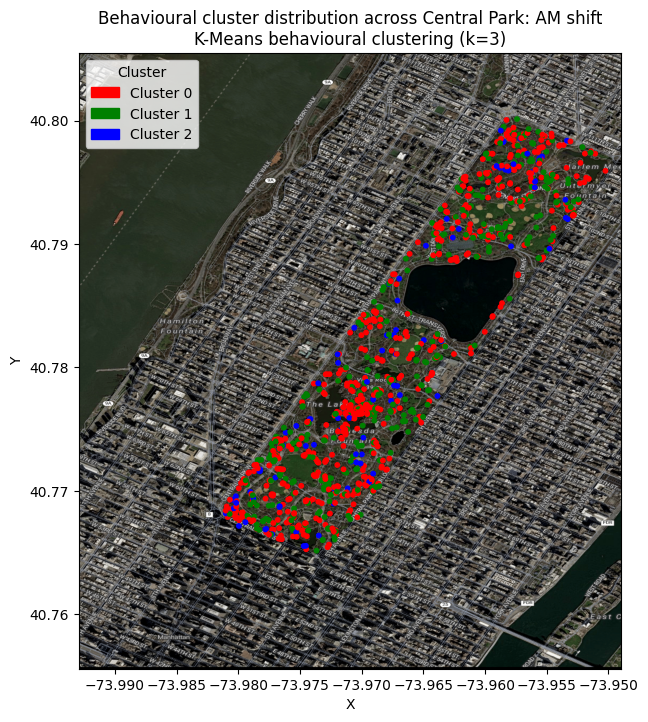

None


In [ ]:
print(behavioural_cluster(am_squirrels, am_behaviour_data, 3, "AM"))

#### PM  
Perform K-Means clustering for squirrel sightings in PM shift

   Movement_norm  Feeding_norm  Vocalisation_norm  Communication_norm  \
0       0.208333 -3.885781e-16           0.022436            0.060096   
1       0.071484  6.118881e-01           0.009713            0.096737   
2       0.427083  3.750000e-02           0.023958            0.106250   

   Human_interaction_norm  Degree_friendliness_norm  
0                0.062500                  0.536058  
1                0.261849                  0.429487  
2                0.305208                  0.279687  


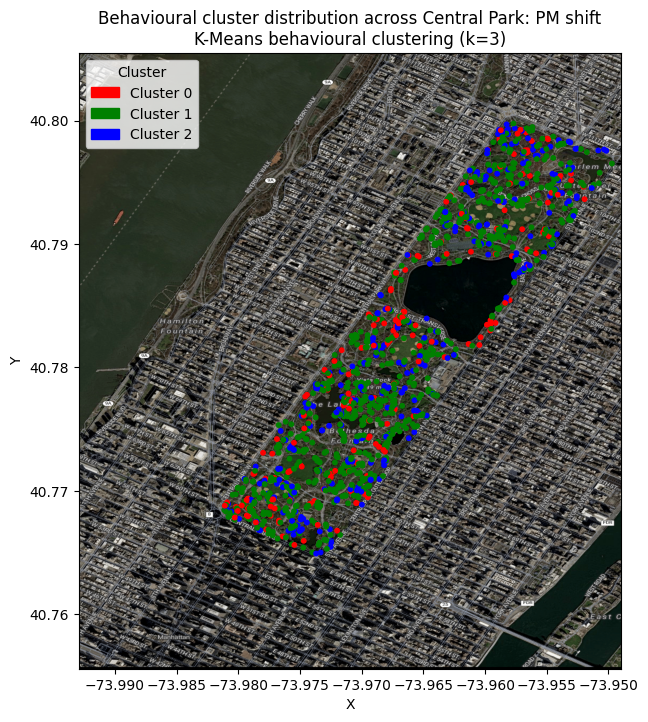

None


In [ ]:
print(behavioural_cluster(pm_squirrels, pm_behaviour_data, 3, "PM"))

Cluster 0 (red): Dominant behaviour: Very high feeding, low movement

Cluster 1 (green): High human interaction

Cluster 2 (blue): Highest movement

-> Both shifts produce the same two behavioral archetypes — Feeders and Movers — confirming that squirrel behaviour organises   
  around activity type rather than time of day. The PM shift just splits the "feeder" group into two (active vs passive
  foragers), likely because PM has more squirrels overall.    

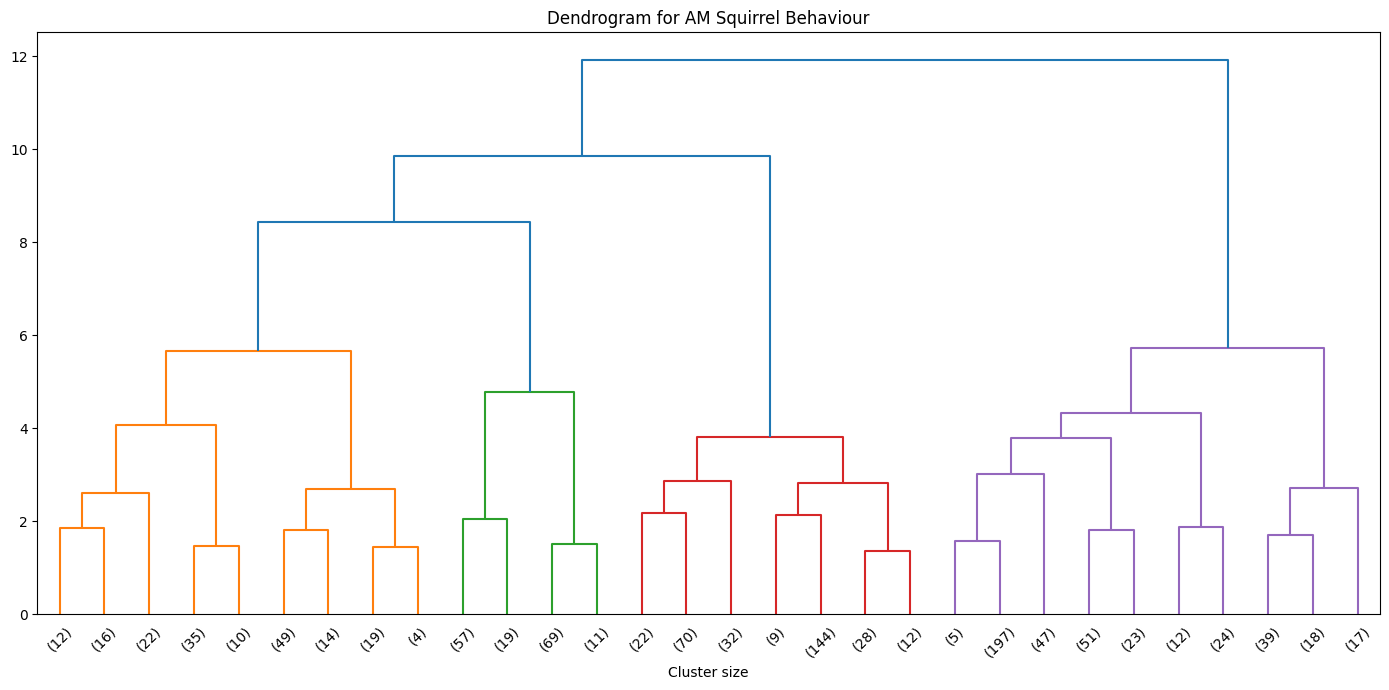

In [ ]:
# Perform hierarchical clustering for AM using ward linkage
linked = linkage(am_behaviour_data, 'ward')

plt.figure(figsize=(14, 7))
dendrogram(linked,
           orientation='top',
           truncate_mode='lastp',
           p=30,
           distance_sort='descending',
           show_leaf_counts=True)

plt.title('Dendrogram for AM Squirrel Behaviour')
plt.xlabel('Cluster size')
plt.tight_layout()
plt.show()



                      Movement_norm  Feeding_norm  Vocalisation_norm  \
hierarchical_cluster                                                   
0                          0.085450      0.596998           0.007698   
1                          0.331230      0.000000           0.025237   
2                          0.224359      0.243590           0.019231   
3                          0.208103      0.372928           0.020258   

                      Communication_norm  Human_interaction_norm  \
hierarchical_cluster                                               
0                               0.012702                0.285604   
1                               0.003155                0.218717   
2                               0.000000                0.350427   
3                               0.519337                0.270718   

                      Degree_friendliness_norm  
hierarchical_cluster                            
0                                     0.521940  
1          

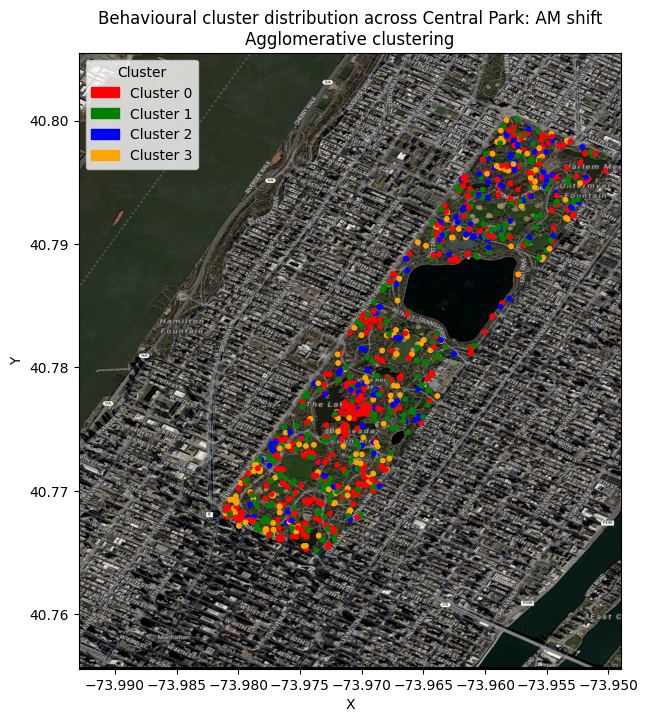

In [ ]:
# Extract cluster labels from dendrogram/linkage result
N_CLUSTERS = 4

am_squirrels = squirrels[squirrels['Shift'] == 'AM'].copy()

am_squirrels['hierarchical_cluster'] = fcluster(
    linked,
    t=N_CLUSTERS,
    criterion='maxclust'
) - 1

# Summarise average behavioural features per cluster
cluster_summary = am_squirrels.groupby('hierarchical_cluster')[
    ENGINEERED_FEATURES_NORM
].mean()

print(cluster_summary)

plot_scatter_chart(
    am_squirrels['X'],
    am_squirrels['Y'],
    "Behavioural cluster distribution across Central Park: AM shift\n"
    "Agglomerative clustering",
    'X',
    'Y',
    COLOUR_MAP,
    am_squirrels['hierarchical_cluster']
)

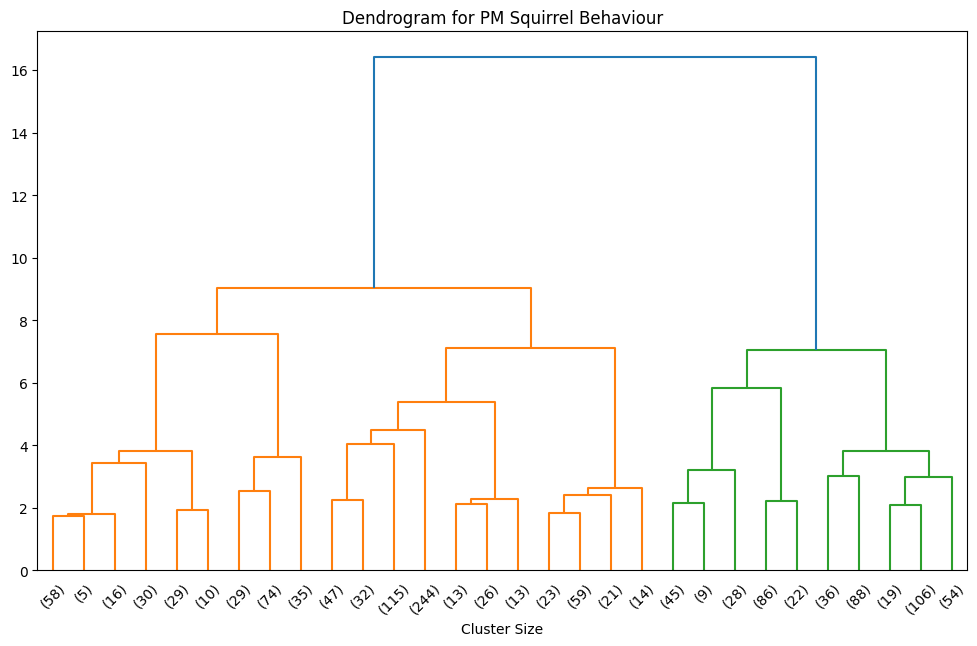

In [ ]:
linked = linkage(pm_behaviour_data, 'ward')

plt.figure(figsize=(12, 7))
dendrogram(linked,
           orientation='top',
           truncate_mode='lastp',
           p=30,
           distance_sort='descending',
           show_leaf_counts=True)
plt.title('Dendrogram for PM Squirrel Behaviour')
plt.xlabel('Cluster Size')
plt.show()


                      Movement_norm  Feeding_norm  Vocalisation_norm  \
hierarchical_cluster                                                   
0                          0.085450      0.596998           0.007698   
1                          0.331230      0.000000           0.025237   
2                          0.224359      0.243590           0.019231   
3                          0.208103      0.372928           0.020258   

                      Communication_norm  Human_interaction_norm  \
hierarchical_cluster                                               
0                               0.012702                0.285604   
1                               0.003155                0.218717   
2                               0.000000                0.350427   
3                               0.519337                0.270718   

                      Degree_friendliness_norm  
hierarchical_cluster                            
0                                     0.521940  
1          

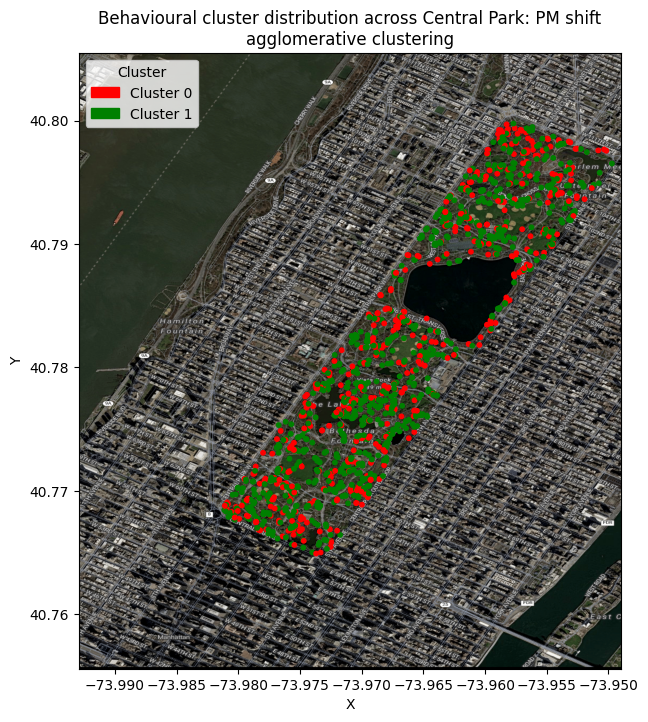

In [ ]:
# Extract cluster labels from dendrogram/linkage result
N_CLUSTERS = 2

pm_squirrels = squirrels[squirrels['Shift'] == 'PM'].copy()

pm_squirrels['hierarchical_cluster'] = fcluster(
    linked,
    t=N_CLUSTERS,
    criterion='maxclust'
) - 1

# Summarise average behavioural features per cluster
cluster_summary = am_squirrels.groupby('hierarchical_cluster')[
    ENGINEERED_FEATURES_NORM
].mean()

print(cluster_summary)

plot_scatter_chart(
    pm_squirrels['X'],
    pm_squirrels['Y'],
    "Behavioural cluster distribution across Central Park: PM shift\n"
    "agglomerative clustering",
    'X',
    'Y',
    COLOUR_MAP,
    pm_squirrels['hierarchical_cluster']
)